# Reservation-based charging：出发前等待诊断（非学习）

新增实验，读取 `results/nyc_charging_deferral_20261022`，所有图保存在该目录的 `figures/`。原 `plot_nyc_charging_rollout.ipynb`、`plot_real_conservative_charging.ipynb` 以及旧结果和图保持原样。

沿用 burst / staggered、0–9 配对种子、1000 车（500 AEV + 500 HEV）、3 个 AEV 站 × 50 plugs、4 小时、30 秒步长。Reactive 对应 `current`；Reservation-based 对应 `real_conservative`。使用原有 OR-Tools + SSG 最大充电准入数/最小行驶时间的固定目标，无价值网络、无训练、无乘客服务或 relocation。

这是完整配置对比：严格模式包含原有预约绑定、运动/完成时序一致性修复，不能解释成只切换一个 mask 的因果消融。

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'benchmark_charging_deferral.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.analyze_charging_deferral import load_results, summarize, plot
RESULTS_DIR = ROOT/'results/nyc_charging_deferral_20261022'
result = plot(summarize(load_results(RESULTS_DIR)))
print(f"Validated {len(result['summary'])} runs; each complete run is one independent replicate.")
display(result['validation'])


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Using fallback logging instead of TensorBoard to avoid protobuf compatibility issues


Validated 40 runs; each complete run is one independent replicate.


,scenario,seed,policy,mode,released,affected,vehicle_epochs,spells,queue_violations
0,burst,0,current,Reactive,455,0,0,0,309
1,burst,0,real_conservative,Reservation-based,455,296,62685,296,0
2,burst,1,current,Reactive,455,0,0,0,305
3,burst,1,real_conservative,Reservation-based,455,294,60693,294,0
4,burst,2,current,Reactive,455,0,0,0,298
5,burst,2,real_conservative,Reservation-based,455,288,58113,288,0
6,burst,3,current,Reactive,455,0,0,0,297
7,burst,3,real_conservative,Reservation-based,455,282,57284,282,0
8,burst,4,current,Reactive,455,0,0,0,303
9,burst,4,real_conservative,Reservation-based,455,290,60042,290,0


## 判定与统计单位

- **新请求 cohort**：AEV 已释放的单次充电需求，排除初始 30 辆正在充电、15 辆已在途车辆。每次 455 个新请求。
- **C0**：通过可达性/站点权限/正充电时长等非预约检查的候选，尚未经过已承诺全窗口与当前候选虚拟预约筛选。额外保存已承诺全窗口通过数和同状态 Reactive 通过数。
- **B**：C0 非空，但所有充电边被 RB 准入删除；**D**：B 成立，且完整动作展开后实际原地等待；**F**：D 且原始实验图无其他非等待动作。本实验 charge/wait-only，F=D。这不证明 NYC 运营图也必然只剩等待。
- 同请求连续 D=1 合并为一个 spell；累计实际等待秒数，绝不累计虚拟 `start-arrival`。未结束 spell 计入观察时长，并标右删失。
- 选后可插入诊断：冻结真实旧承诺 + 实际新选预约，删除未选虚拟区间，检查一辆被挡车能否单独插入。**多辆各自可插入不等于能同时插入，也不是排程全局最优判断。**
- 附加电量诊断：使用生产 relocation mask，排除零位移动作；另给出20% reserve 下的服务总行程上界。无真实客运订单，不能把服务选项为空全部归因于电量，也不能排除任意短的同区订单。
- 表格和误差棒为每场景 **10 个完整运行的均值 ± 样本标准差**；另列同 seed 差值的未校正 95% t 区间。车辆、时间步和三种等待计数都不是独立实验重复。

In [2]:
metrics = ['affected_pct', 'deferral_spells', 'blocked_vehicle_minutes', 'blocked_minutes_per_new_request',
           'not_started_by_H_pct', 'post_selection_slot_feasible_requests', 'no_relocation_affected_requests',
           'never_base_candidate_requests', 'affected_not_started_by_H']
display(result['statistics'].loc[(result['statistics'].policy=='real_conservative') & result['statistics'].metric.isin(metrics)].round(3))
print('论文补充表（新请求 cohort）：')
print(result['latex'])


,scenario,policy,mode,metric,n,mean,sd
18,burst,real_conservative,Reservation-based,affected_pct,10,63.495,1.179
19,burst,real_conservative,Reservation-based,deferral_spells,10,288.900,5.363
20,burst,real_conservative,Reservation-based,blocked_vehicle_minutes,10,29872.300,864.744
21,burst,real_conservative,Reservation-based,blocked_minutes_per_new_request,10,65.653,1.901
22,burst,real_conservative,Reservation-based,not_started_by_H_pct,10,10.198,1.088
23,burst,real_conservative,Reservation-based,post_selection_slot_feasible_requests,10,285.100,6.855
24,burst,real_conservative,Reservation-based,no_relocation_affected_requests,10,2.500,1.650
28,burst,real_conservative,Reservation-based,never_base_candidate_requests,10,46.400,4.949
29,burst,real_conservative,Reservation-based,affected_not_started_by_H,10,0.000,0.000
50,staggered,real_conservative,Reservation-based,affected_pct,10,59.363,1.170


论文补充表（新请求 cohort）：
\begin{table*}[!t]
\centering\small
\caption{Admission-blocked pre-departure waiting under reservation-based charging. Mean $\pm$ sample SD across ten complete runs per scenario. The cohort excludes 30 initially charging and 15 initially inbound AEVs. Unfinished waits contribute their observed duration.}
\label{tab:charging-admission-deferral}
\begin{tabular}{lrrrrrr}
\toprule
Scenario & New requests & Deferred (\%) & Spells/run & Wait (veh-min/run) & Wait/request (min) & Not started by $H$ (\%) \\
\midrule
Burst & $455.00 \pm 0.00$ & $63.49 \pm 1.18$ & $288.90 \pm 5.36$ & $29872.30 \pm 864.74$ & $65.65 \pm 1.90$ & $10.20 \pm 1.09$ \\
Staggered & $455.00 \pm 0.00$ & $59.36 \pm 1.17$ & $270.10 \pm 5.32$ & $13958.10 \pm 889.39$ & $30.68 \pm 1.95$ & $10.20 \pm 1.09$ \\
\bottomrule
\end{tabular}
\end{table*}


## 等待是否被转移

三个面板使用完全相同的新请求 cohort，分母包含零等待、未出发和未开始充电的请求。

前两项是实际出发前原地驻留、站内等待；第三项为从请求释放到开始充电的窗口内截断延迟，包含行驶。到 H 尚未开始的请求不能删除；以 H 截断，并单独报告数量。站内等待采用实际 arrival/start 时间差，与旧图包含初始车辆的队列面积不是同一统计口径。

论文用图去掉顶部总标题，保留三个面板指标名；同 cohort、10 个配对 seed 和 sample SD 的说明放入附录图注。

,scenario,policy,mode,metric,n,mean,sd
9,burst,current,Reactive,mean_predeparture_wait_minutes,10,24.475,2.610
10,burst,current,Reactive,mean_station_wait_minutes,10,62.442,2.652
11,burst,current,Reactive,mean_time_to_start_truncated_minutes,10,90.896,1.510
14,burst,current,Reactive,new_completed_requests,10,371.600,7.706
25,burst,real_conservative,Reservation-based,mean_predeparture_wait_minutes,10,90.128,0.883
26,burst,real_conservative,Reservation-based,mean_station_wait_minutes,10,0.000,0.000
27,burst,real_conservative,Reservation-based,mean_time_to_start_truncated_minutes,10,95.615,0.818
30,burst,real_conservative,Reservation-based,new_completed_requests,10,363.400,4.427
41,staggered,current,Reactive,mean_predeparture_wait_minutes,10,42.781,1.205
42,staggered,current,Reactive,mean_station_wait_minutes,10,3.682,0.319


,scenario,metric,comparison,n,mean,sd,ci95_low,ci95_high
0,burst,mean_predeparture_wait_minutes,RB minus Reactive,10,65.653,1.901,64.294,67.013
1,burst,mean_station_wait_minutes,RB minus Reactive,10,-62.442,2.652,-64.340,-60.545
2,burst,mean_time_to_start_truncated_minutes,RB minus Reactive,10,4.719,1.378,3.733,5.705
3,burst,new_completed_requests,RB minus Reactive,10,-8.200,7.829,-13.800,-2.600
4,staggered,mean_predeparture_wait_minutes,RB minus Reactive,10,6.213,0.384,5.938,6.487
5,staggered,mean_station_wait_minutes,RB minus Reactive,10,-3.682,0.319,-3.910,-3.454
6,staggered,mean_time_to_start_truncated_minutes,RB minus Reactive,10,1.576,0.190,1.440,1.713
7,staggered,new_completed_requests,RB minus Reactive,10,-2.000,4.522,-5.235,1.235


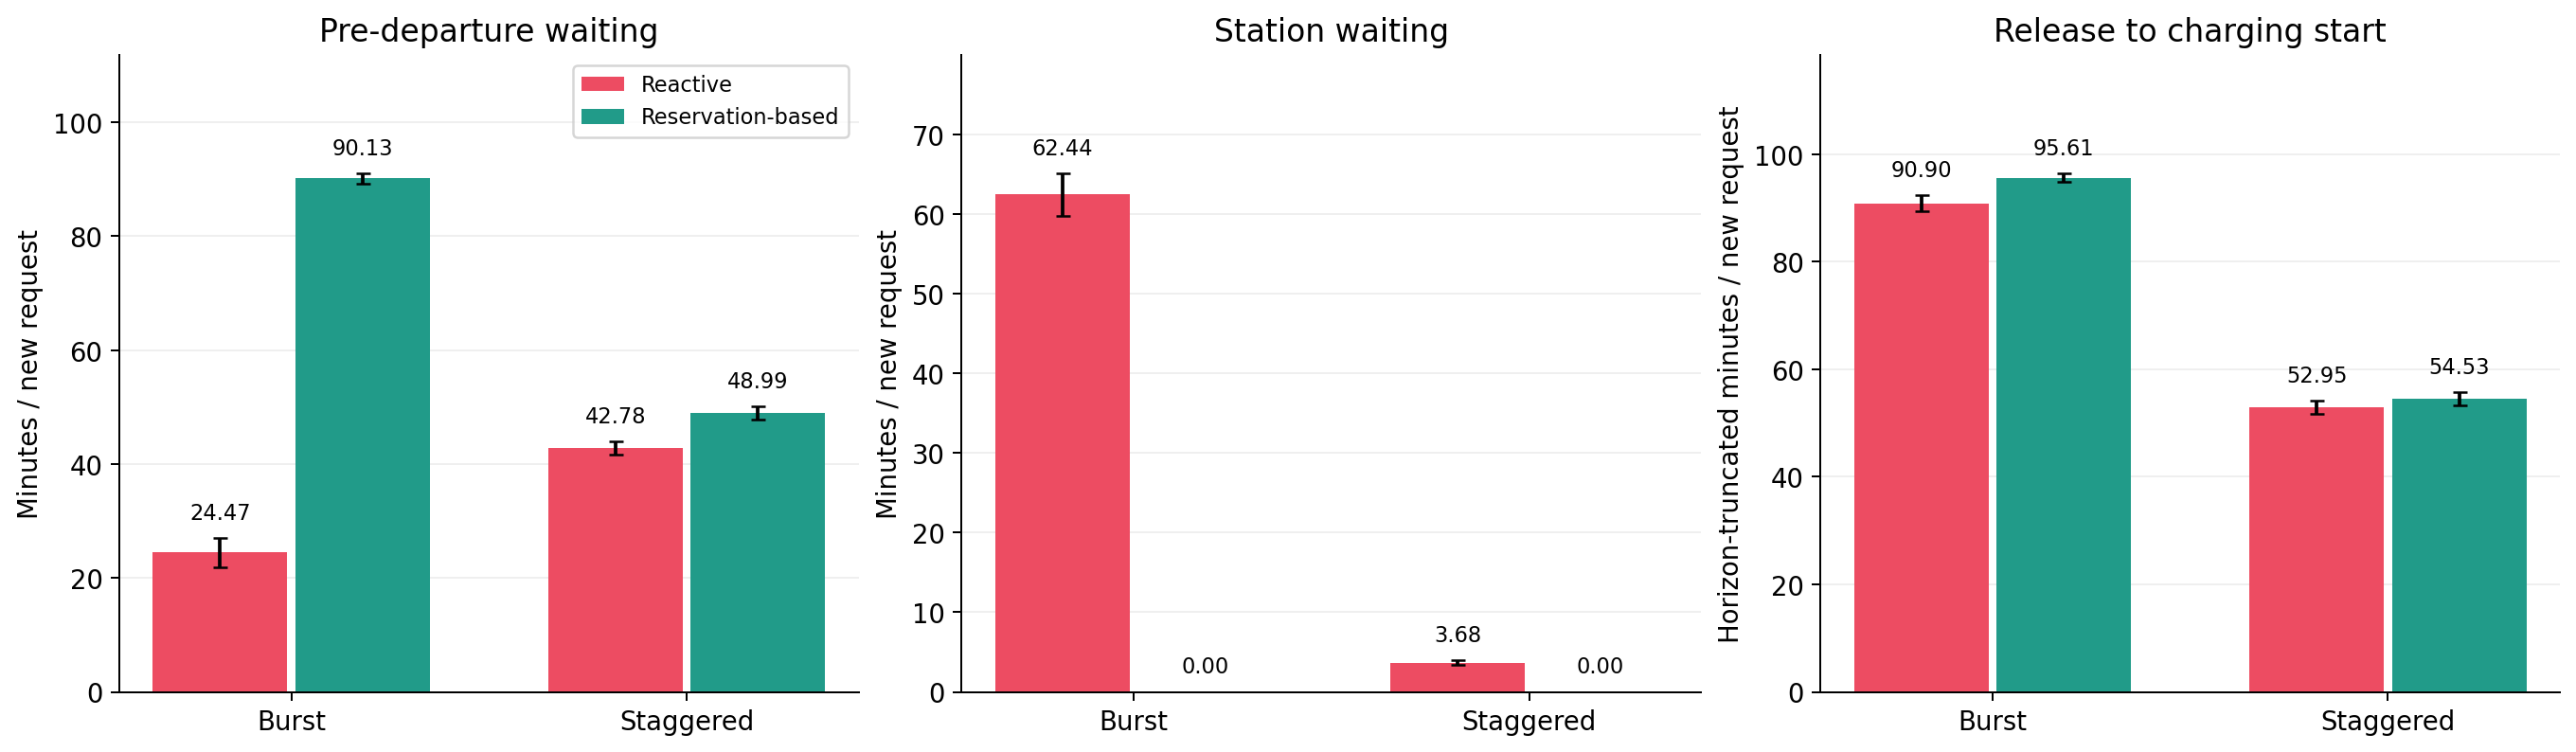

In [3]:
display(result['statistics'].loc[result['statistics'].metric.isin([
    'mean_predeparture_wait_minutes','mean_station_wait_minutes','mean_time_to_start_truncated_minutes','new_completed_requests'])].round(3))
display(result['paired'].round(3))
display(Image(filename=str(RESULTS_DIR/'figures/01_wait_location_and_delay.png')))


## 低电量实例

完整的汇总不挑 seed。下面的实例按“无可行正位移 relocation、存在选后插入机会、低 SoC”排序，只用于展示事件链。完整请求、spell 和压缩逐步日志另存，所有计数来自全部记录。

服务距离上界 = `(SoC - 0.20) / 每公里耗电比例`，包含接客与载客距离；若下车点需要更高充电储备，实际允许距离更小。它不等于当前存在或实际执行了客运订单。

,scenario,seed,vehicle_id,soc_pct,epoch,pre_candidates,admitted_candidates,service_distance_budget_m,wait_minutes,blocked_minutes,post_selection_fitting_stations
0,staggered,1,737,20.00192,127,1,0,6.88810,131.0,131.0,[9000001]
1,burst,0,641,20.00380,0,2,0,13.62706,65.5,65.5,[9000002]
2,burst,0,707,20.00443,0,2,0,15.90047,150.5,150.5,"[9000002, 9000004]"
3,staggered,3,943,20.00641,214,2,0,22.97056,0.5,0.5,"[9000001, 9000002]"
4,staggered,9,872,20.01542,177,1,0,55.31127,95.5,95.5,[9000004]
5,burst,6,758,20.01793,0,1,0,64.28912,148.5,148.5,[9000001]
6,burst,5,665,20.03173,0,2,0,113.76757,88.0,88.0,"[9000002, 9000004]"
7,burst,6,628,20.03428,0,2,0,122.92496,5.0,5.0,[9000002]
8,burst,0,971,20.03835,0,1,0,137.51435,160.0,160.0,[9000001]
9,staggered,0,647,20.03835,203,2,0,137.51435,4.0,4.0,[9000002]


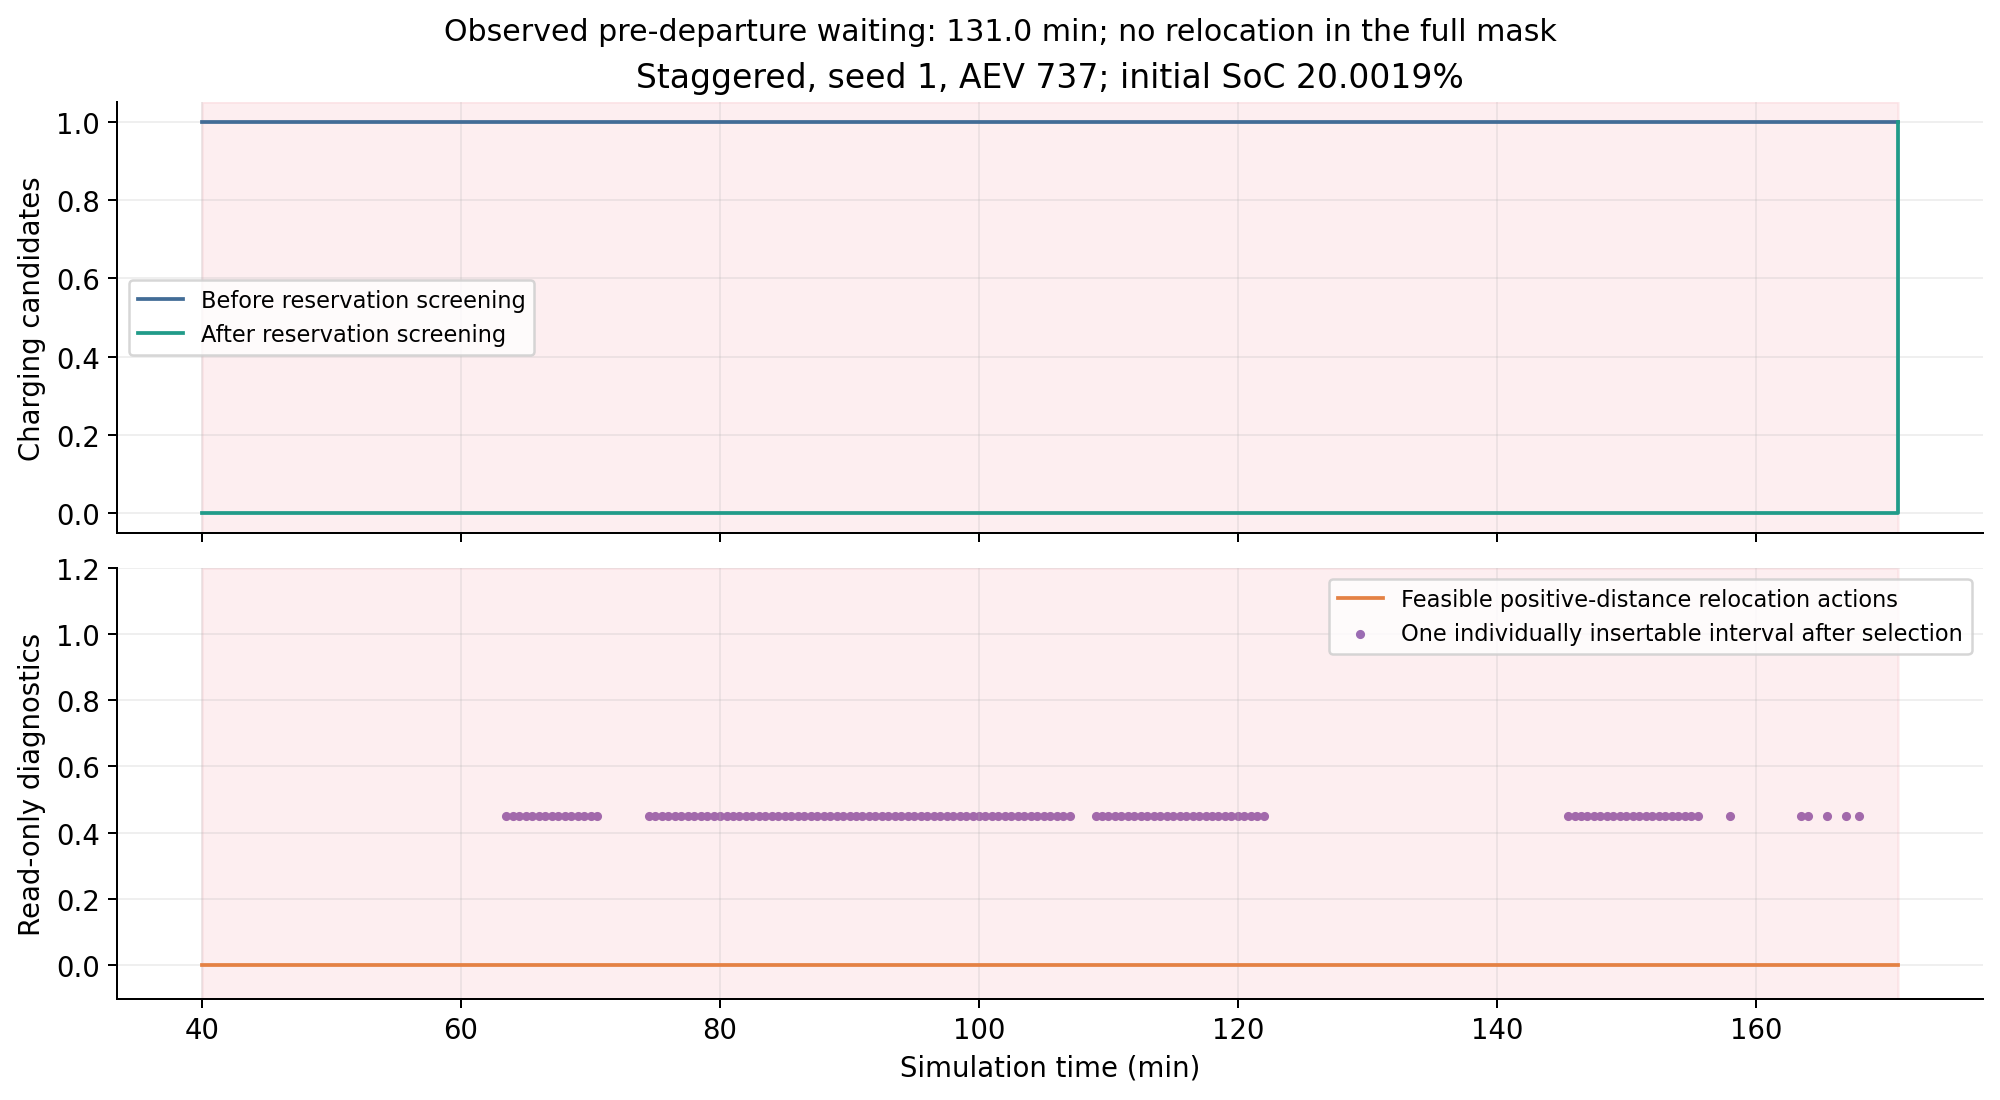

全部数据: /Users/seinzhou/Desktop/icaps/results/nyc_charging_deferral_20261022
逐步日志: 每次运行的 deferral_decisions.jsonl.gz（流式写入，避免全量驻留 RAM）


In [4]:
display(result['case_table'].head(20).round(5))
display(Image(filename=str(RESULTS_DIR/'figures/02_low_soc_deferral_case.png')))
print('全部数据:', RESULTS_DIR)
print('逐步日志: 每次运行的 deferral_decisions.jsonl.gz（流式写入，避免全量驻留 RAM）')
